<a href="https://colab.research.google.com/github/gosiapiechaczek/Analysis-of-account-creation-trends-and-user-activity-in-the-context-of-email-/blob/main/Analysis_of_the_company%E2%80%99s_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

drive.mount('/content/drive')

%cd /content/drive/MyDrive/Pandas

events = pd.read_csv("/content/drive/MyDrive/Pandas/events.csv")
products = pd.read_csv("/content/drive/MyDrive/Pandas/products.csv")
countries = pd.read_csv("/content/drive/MyDrive/Pandas/countries.csv")

print("Events:", events.shape)
print("Products:", products.shape)
print("Countries:", countries.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Pandas
Events: (1330, 10)
Products: (12, 2)
Countries: (249, 5)


# Wstępne zapoznanie





In [ ]:
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79



*   Order ID - identyfikator zamówienia
*   Order Date - data zamówienia
*   Ship Date - data wysyłki
*   Order Priority - priorytet zamówienia H (High), M (Medium), L (Low), C (Critical)
*   Country Code - kod kraju
*   Product ID - identyfikator produktu
*   Sales Channel - kanał sprzedaży
*   Units Sold - liczba sprzedanych sztuk produktu
*   Unit Price - cena sprzedaży
*   Unit Cost - koszt sztuki

In [ ]:
products.head()

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies



*   id - identyfikator zamówienia
*   item_type - typ produktu




In [ ]:
countries.head()

,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia



*   name - nazwa kraju
*   alpha-2 - dwuliterowy kod kraju
*   alpha-3 - trzyliterowy kod kraju
*   region - nazwa regionu
*   sub-region - nazwa podregionu





Tabela events jest połączona z tabelą products za pomocą Product ID w events oraz id w products. Natomiast events i countries są połączone za pomocą Country Code w events oraz alpha-3 w countries.

# Czyszczenie danych

In [ ]:
# Sprawdzanie brakujących wartości
print(events.isna().sum())
print(events.isna().sum() / events.shape[0] * 100)

print(products.isna().sum())
print(products.isna().sum() / products.shape[0] * 100)

print(countries.isna().sum())
print(countries.isna().sum() / countries.shape[0] * 100)

Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         2
Unit Price         0
Unit Cost          0
dtype: int64
Order ID          0.000000
Order Date        0.000000
Ship Date         0.000000
Order Priority    0.000000
Country Code      6.165414
Product ID        0.000000
Sales Channel     0.000000
Units Sold        0.150376
Unit Price        0.000000
Unit Cost         0.000000
dtype: float64
id           0
item_type    0
dtype: int64
id           0.0
item_type    0.0
dtype: float64
name          0
alpha-2       1
alpha-3       0
region        1
sub-region    1
dtype: int64
name          0.000000
alpha-2       0.401606
alpha-3       0.000000
region        0.401606
sub-region    0.401606
dtype: float64


Brak danych w kolumnie Country Code to aż 6%. Jest to problemem, ponieważ jest on kluczem, który pozwala połączyć events z countries. Możliwe przyczyny to brak danych podczas rejestracji zamówienia,
błąd podczas importowania danych lub brak przypisanego kraju do konkretnego zamówienia. Kilku danych brakuje również w Units Sold, alpha-2, region i sub-region.

In [ ]:
events[events["Country Code"].isna()]

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
13,104548490,1/1/2014,1/5/2014,M,NaN,7331,Online,7076.0,255.28,159.42
26,117929494,1/24/2015,3/2/2015,H,NaN,4594,Offline,6813.0,9.33,6.92
29,118859469,6/2/2011,7/1/2011,L,NaN,8969,Offline,2013.0,152.58,97.44
43,126948583,5/24/2017,7/9/2017,C,NaN,7331,Online,5762.0,255.28,159.42
...,...,...,...,...,...,...,...,...,...,...
1213,919922006,8/27/2011,9/18/2011,L,NaN,4594,Online,4219.0,9.33,6.92
1220,922564303,3/17/2017,4/2/2017,L,NaN,7940,Offline,6134.0,668.27,502.54
1250,941061675,3/8/2017,3/20/2017,M,NaN,5988,Offline,9917.0,154.06,90.93
1296,975080668,7/23/2017,8/20/2017,C,NaN,5988,Offline,6893.0,154.06,90.93


W tabeli events znajduje się 82 rekordy z brakującym Country Code. Pozostałe informacje dotyczące tych zamówień są kompletne, dlatego nie decyduję się na ich usunięcie. Nie ma wystarczających informacji pozwalających wiarygodnie uzupełnić brakujące kody krajów. W związku z tym wartości zostawiam jako NaN. Rekordy te mogę wykorzystać w analizach niezależnych od kraju.

In [ ]:
# Uzupełniam brakujące dane w Units Sold średnią arytmetyczną i zamieniam typ z float na int
mean_units = events["Units Sold"].mean()
print(mean_units)

events["Units Sold"] = events["Units Sold"].fillna(mean_units)

events["Units Sold"] = events["Units Sold"].fillna(events["Units Sold"].mean()).astype(int)
events.info()


4952.201807228916
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1330 non-null   int64  
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(2), int64(3), object(5)
memory usage: 104.0+ KB


In [ ]:
# Uzupełnianie braków w alpha-2, region, sub-region
countries[countries["alpha-2"].isna() | countries["region"].isna() | countries["sub-region"].isna()]

,name,alpha-2,alpha-3,region,sub-region
8,Antarctica,AQ,ATA,NaN,NaN
153,Namibia,NaN,NAM,Africa,Sub-Saharan Africa


Brak wartości region i sub-region dla Antarktydy, zostawiam jako NaN, ponieważ brakuje wiarygodnego źródła informacji. Nambię mogę uzupełnić kodem "NA"

In [ ]:
# Dla Namibia mogę uzupełnić kod alpha-2 jako "NA"
countries["alpha-2"] = countries["alpha-2"].fillna("NA")
countries[countries["name"] == "Namibia"]

,name,alpha-2,alpha-3,region,sub-region
153,Namibia,NA,NAM,Africa,Sub-Saharan Africa


In [ ]:
# Sprawdzanie typu danych
events.info()
products.info()
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
mem

Order Date i Ship Date są rozpoznane jako object. Trzeba zmienić na datetime

In [ ]:
# Zmiana typu danych na datę
events["Order Date"] = pd.to_datetime(events["Order Date"], format="%m/%d/%Y")
events["Ship Date"] = pd.to_datetime(events["Ship Date"], format="%m/%d/%Y")
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1330 non-null   int64         
 1   Order Date      1330 non-null   datetime64[ns]
 2   Ship Date       1330 non-null   datetime64[ns]
 3   Order Priority  1330 non-null   object        
 4   Country Code    1248 non-null   object        
 5   Product ID      1330 non-null   int64         
 6   Sales Channel   1330 non-null   object        
 7   Units Sold      1330 non-null   int64         
 8   Unit Price      1330 non-null   float64       
 9   Unit Cost       1330 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(3), object(3)
memory usage: 104.0+ KB


In [ ]:
# Sprawdzanie czy są duplikaty

# events
duplicate_rows = events.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())

# products
duplicate_rows = products.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())

# countries
duplicate_rows = countries.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())

0       False
1       False
2       False
3       False
4       False
        ...  
1325    False
1326    False
1327    False
1328    False
1329    False
Length: 1330, dtype: bool
0
0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
dtype: bool
0
0      False
1      False
2      False
3      False
4      False
       ...  
244    False
245    False
246    False
247    False
248    False
Length: 249, dtype: bool
0


Brak duplikatów

In [ ]:
# Szukanie anomalii w tabeli events
events[events["Units Sold"] < 0]
events[events["Unit Price"] < 0]
events[events["Unit Cost"] < 0]

events[events["Ship Date"] < events["Order Date"]]

events.describe()

,Order ID,Order Date,Ship Date,Product ID,Units Sold,Unit Price,Unit Cost
count,1.330000e+03,1330,1330,1330.000000,1330.000000,1330.000000,1330.000000
mean,5.412048e+08,2013-10-12 06:09:12.180451072,2013-11-06 00:46:33.383458816,5788.096241,4952.201504,264.893541,187.246812
min,1.006406e+08,2010-01-01 00:00:00,2010-01-10 00:00:00,1270.000000,2.000000,9.330000,6.920000
25%,3.190004e+08,2011-12-16 06:00:00,2012-01-03 00:00:00,3127.000000,2360.750000,81.730000,35.840000
50%,5.387164e+08,2013-10-17 00:00:00,2013-11-09 00:00:00,5988.000000,4958.000000,154.060000,97.440000
75%,7.544628e+08,2015-08-28 18:00:00,2015-10-03 18:00:00,8681.000000,7458.750000,437.200000,263.330000
max,9.998797e+08,2017-07-23 00:00:00,2017-08-31 00:00:00,8969.000000,9999.000000,668.270000,524.960000
std,2.573882e+08,NaN,NaN,2820.728878,2903.012170,217.323460,176.158873


Brak anomalii

# Analiza i wizualizacja danych

In [ ]:
# Łączenie trzech tabel w jedną ramkię DataFrame
data = events.merge(products, left_on="Product ID", right_on="id", how="left").merge(countries, left_on="Country Code", right_on="alpha-3", how="left")
data.head()

# Zmiana nazwy kolumn
data.rename(columns={"name": "Country", "item_type": "Category", "region": "Region", "sub-region": "Sub-region"}, inplace=True)
data.head()

# Usuwanie niepotrzebnych do analizy kolumn
data = data.drop(columns=["id", "alpha-2", "alpha-3"])
data.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,Category,Country,Region,Sub-region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650,205.70,117.11,Cereal,Norway,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993,205.70,117.11,Cereal,Serbia,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,NaN,7940,Online,4693,668.27,502.54,Household,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171,109.28,35.84,Clothes,Montenegro,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648,47.45,31.79,Beverages,Serbia,Europe,Southern Europe


In [ ]:
# Kluczowe wskaźniki wydajności firmy:

# Liczba zamówień
print("Total amount of orders:", data["Order ID"].nunique())

# Całkowity zysk
data["Profit"] = data["Units Sold"] * (data["Unit Price"] - data["Unit Cost"])
print("Total profit:", data["Profit"].sum())

# Całkowita liczba krajów zbytu
print("Total amount of countries:", data["Country"].nunique())

# Łączna liczba sprzedanych sztuk
print("Total amount of units sold:", data["Units Sold"].sum())

# Średnia wartość zamówienia
data["Order Value"] = data["Units Sold"] * data["Unit Price"]
print("Average order value:", data["Order Value"].mean())

# Liczba zamówień Online vs Offline
data["Sales Channel"] = data["Sales Channel"].str.lower()
print("Orders by channels:", data.groupby("Sales Channel")["Order ID"].nunique())

Total amount of orders: 1330
Total profit: 501841810.52
Total amount of countries: 45
Total amount of units sold: 6586428
Average order value: 1281671.680037594
Orders by channels: Sales Channel
offline    667
online     663
Name: Order ID, dtype: int64


Łączna liczba zamówień to 1330 na terenie 45 krajów, całkowity zysk wynosi 501841810.52, a średnia wartość zamówienia wynosi 1281671.68. Całkowita ilość sprzedanych produktów to 6586428. Minimalnie więcej sprzedaje się fizycznie.

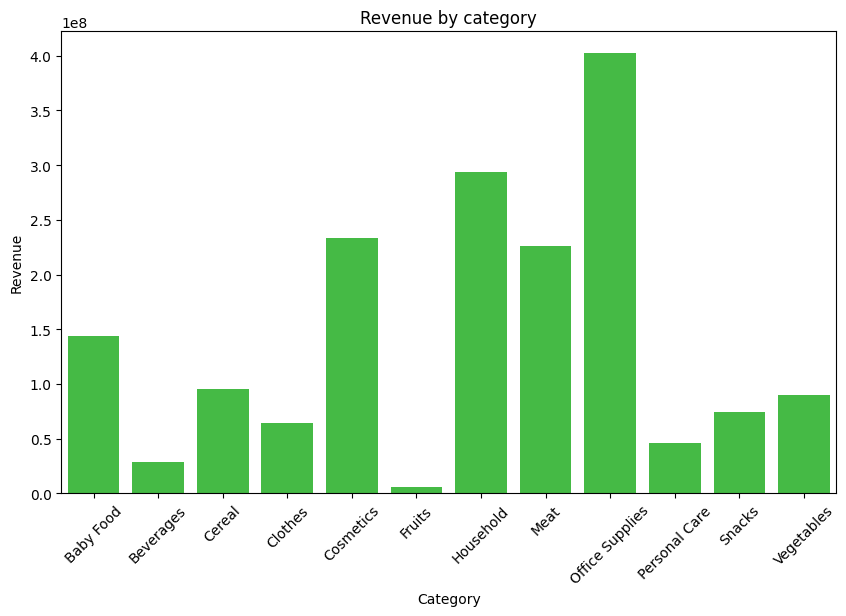

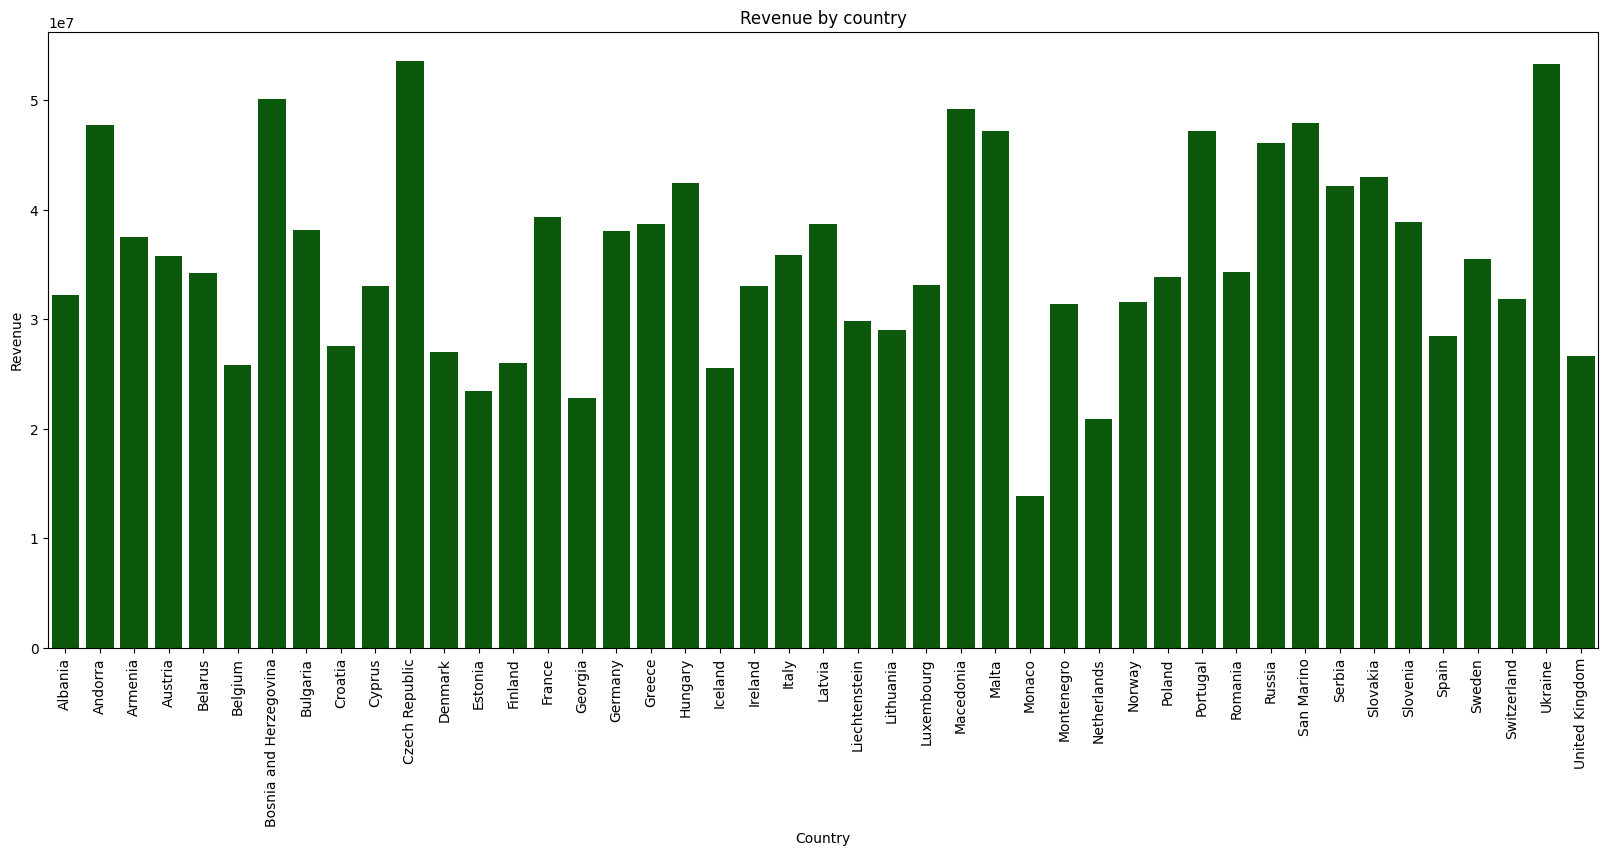

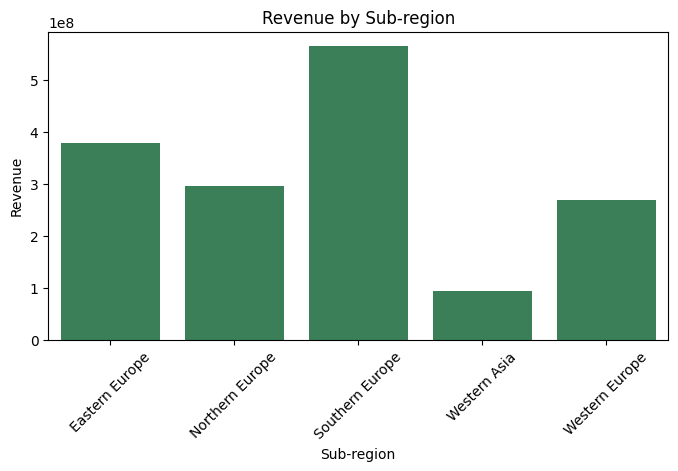

Sales Channel
offline    8.742546e+08
online     8.303688e+08
Name: Revenue, dtype: float64


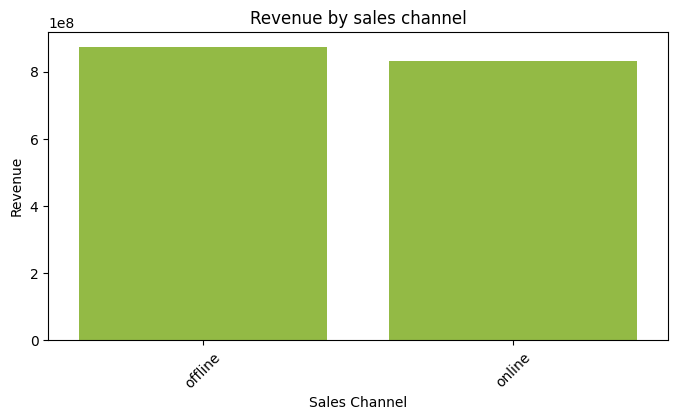

In [ ]:
# Analiza sprzedaży: przychód

# Przychód według kategorii
data["Revenue"] = data["Units Sold"] * data["Unit Price"]

revenue_by_category = data.groupby("Category")["Revenue"].sum()
# Wizualizacja
plt.figure(figsize=(10, 6))
sns.barplot(x=revenue_by_category.index, y=revenue_by_category.values, color="limegreen")
plt.title("Revenue by category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

# Przychód według krajów
revenue_by_country = data.groupby("Country")["Revenue"].sum()
# Wizualizacja
plt.figure(figsize=(20, 8))
sns.barplot(x=revenue_by_country.index, y=revenue_by_country.values, color="darkgreen")
plt.title("Revenue by country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.show()

# Przychód według regionów
revenue_by_subregion = data.groupby("Sub-region")["Revenue"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=revenue_by_subregion.index, y=revenue_by_subregion.values, color="seagreen")
plt.title("Revenue by Sub-region")
plt.xlabel("Sub-region")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

# Przychód według kanałów sprzedaży
revenue_by_channel = data.groupby("Sales Channel")["Revenue"].sum()

# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=revenue_by_channel.index, y=revenue_by_channel.values, color="yellowgreen")
plt.title("Revenue by sales channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

Najwięcej zysku przyniosła kategoria Office Supplies a najmniej Fruits. Największe zyski przynoszą kraje takie jak: Czechy, Ukraina, Bośnia i Harcegowina i region Południowej Europy, a najmniejsze Monako i Holandia i region Azji Zachodniej. Minimalnie większy przychód przynosi sprzedaż fizyczna.

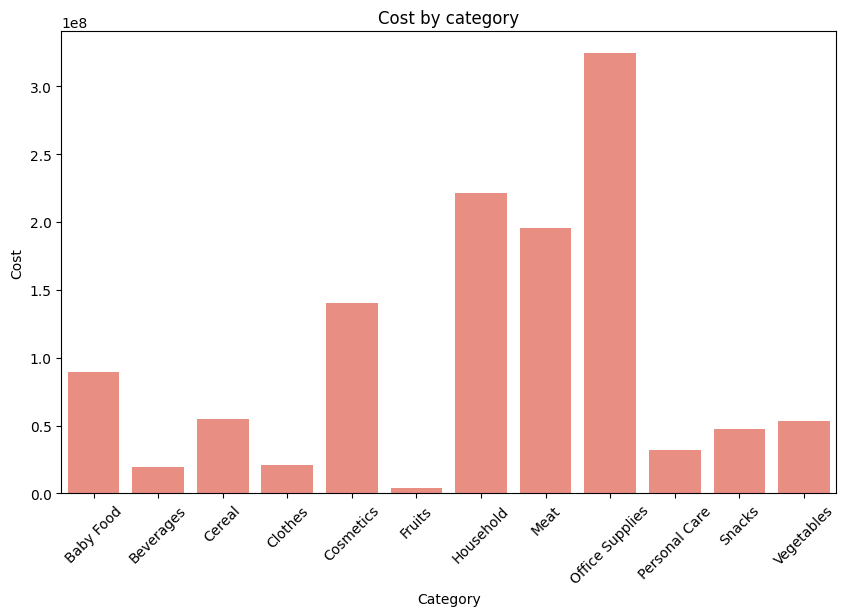

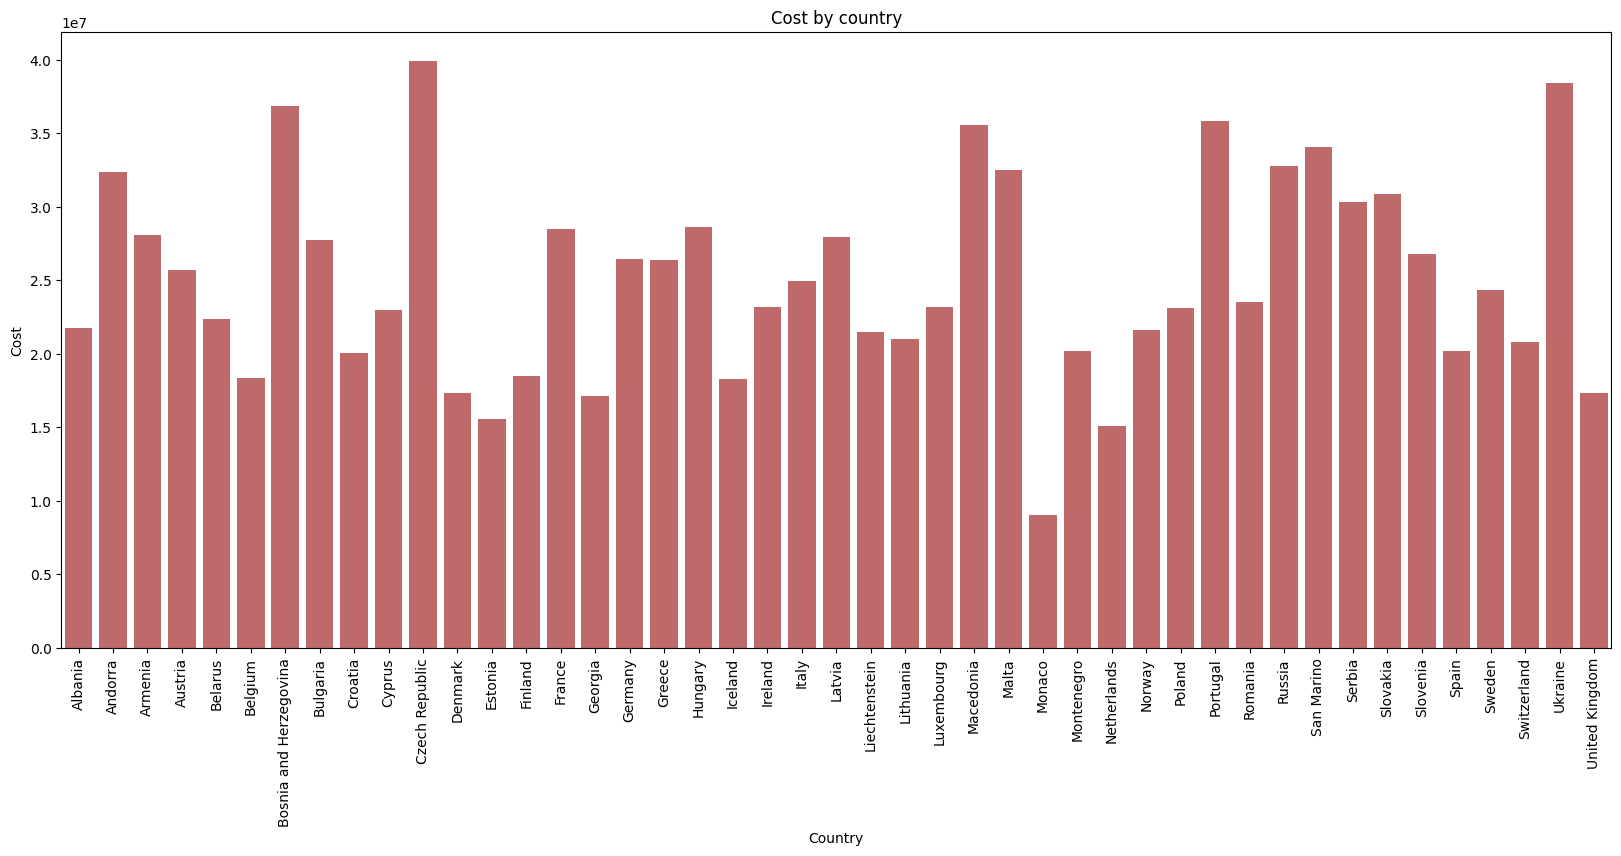

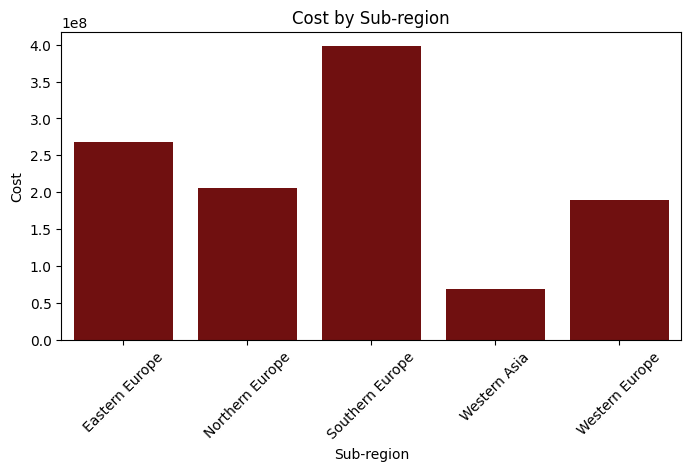

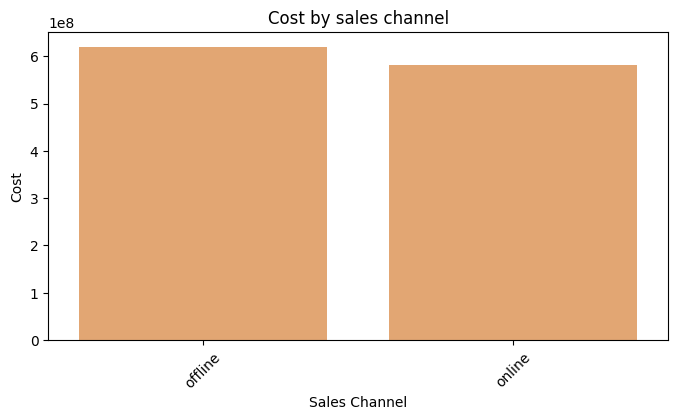

In [ ]:
# Analiza sprzedaży: koszt

# Koszt według kategorii
data["Cost"] = data["Units Sold"] * data["Unit Cost"]

cost_by_category = data.groupby("Category")["Cost"].sum()
# Wizualizacja
plt.figure(figsize=(10, 6))
sns.barplot(x=cost_by_category.index, y=cost_by_category.values, color="salmon")
plt.title("Cost by category")
plt.xlabel("Category")
plt.ylabel("Cost")
plt.xticks(rotation=45)
plt.show()

# Koszt według krajów
cost_by_country = data.groupby("Country")["Cost"].sum()
# Wizualizacja
plt.figure(figsize=(20, 8))
sns.barplot(x=cost_by_country.index, y=cost_by_country.values, color="indianred")
plt.title("Cost by country")
plt.xlabel("Country")
plt.ylabel("Cost")
plt.xticks(rotation=90)
plt.show()

# Koszt według regionów
cost_by_subregion = data.groupby("Sub-region")["Cost"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=cost_by_subregion.index, y=cost_by_subregion.values, color="maroon")
plt.title("Cost by Sub-region")
plt.xlabel("Sub-region")
plt.ylabel("Cost")
plt.xticks(rotation=45)
plt.show()

# Koszt według kanałów sprzedaży
cost_by_channel = data.groupby("Sales Channel")["Cost"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=cost_by_channel.index, y=cost_by_channel.values, color="sandybrown")
plt.title("Cost by sales channel")
plt.xlabel("Sales Channel")
plt.ylabel("Cost")
plt.xticks(rotation=45)
plt.show()

Najwyższy koszt występuje w kategorii Office Supplies, w krajach takich jak Czechy i Ukraina, a najniższy w kategorii Fruits w krajach takich jak Monako i Holandia. Najwyższe koszty są w Europie Południowej a najniższe w Azji Zachodniej. Koszty są minimalnie wyższe w kanale Offline

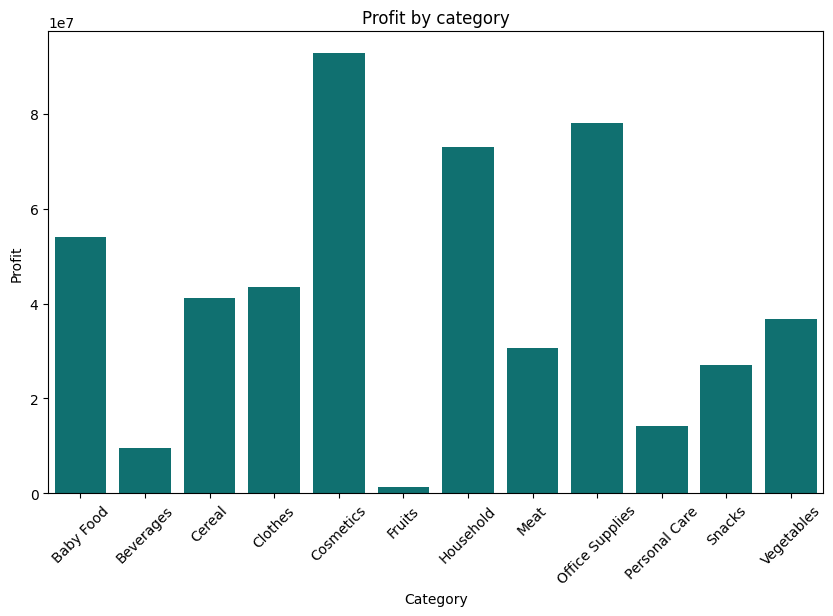

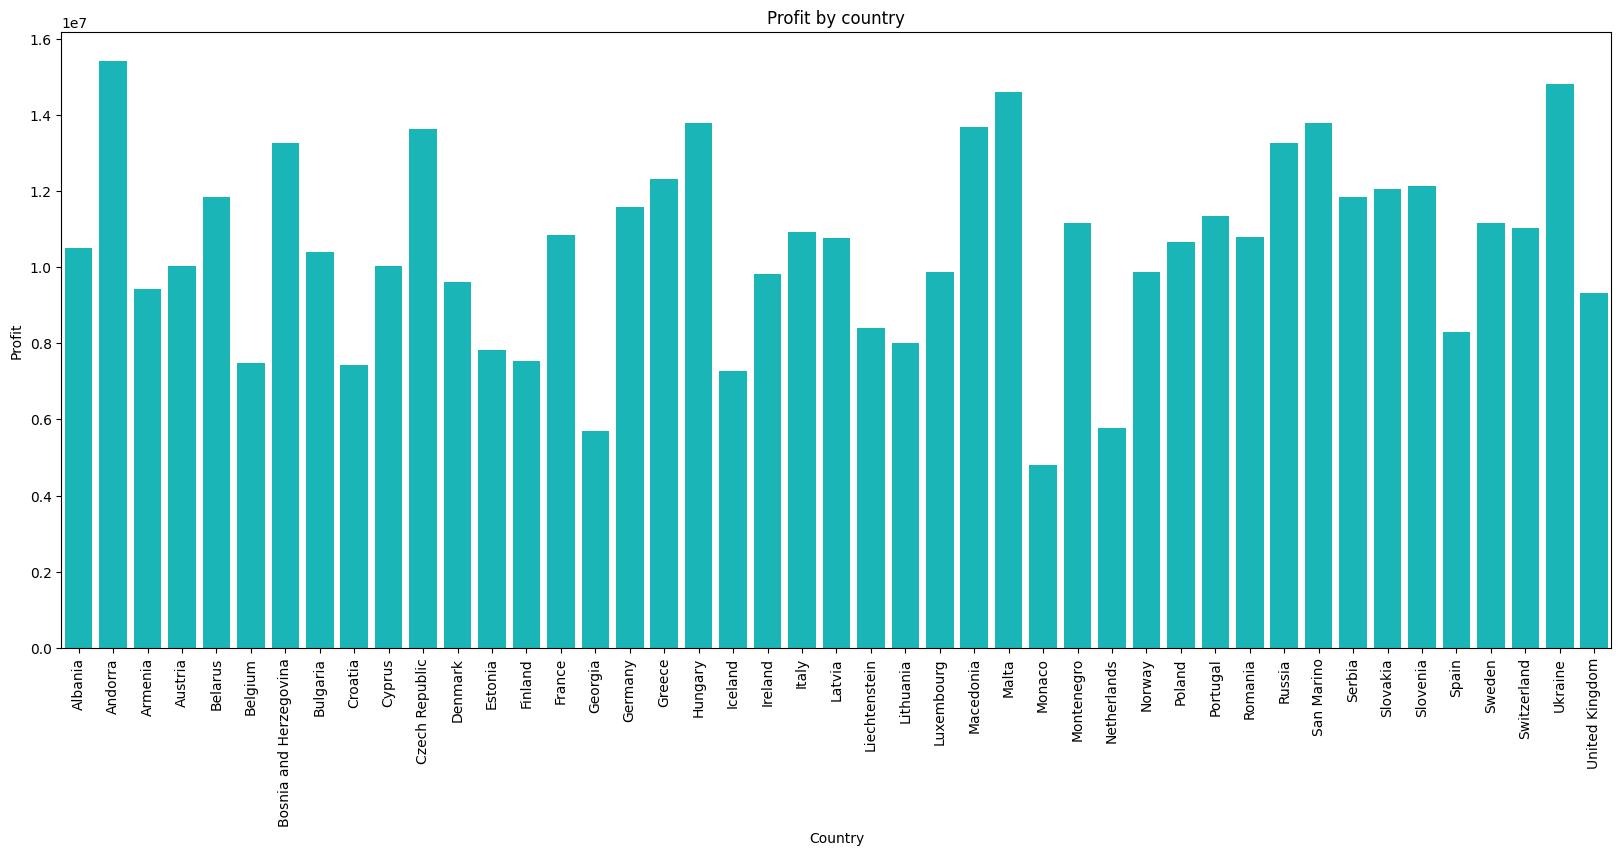

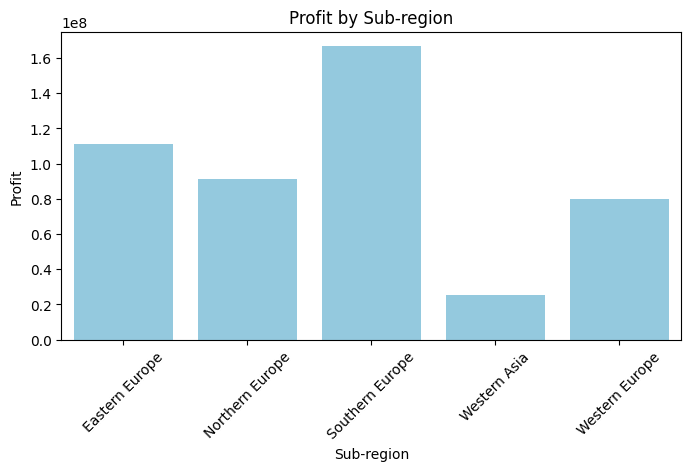

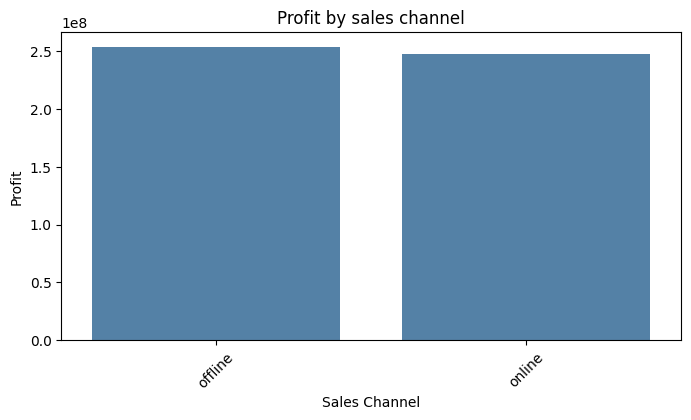

In [ ]:
# Analiza sprzedaży: zysk

# Zysk według kategorii
data["Profit"] = data["Revenue"] - data["Cost"]

profit_by_category = data.groupby("Category")["Profit"].sum()
# Wizualizacja
plt.figure(figsize=(10, 6))
sns.barplot(x=profit_by_category.index, y=profit_by_category.values, color="teal")
plt.title("Profit by category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

# Zysk według krajów
profit_by_country = data.groupby("Country")["Profit"].sum()
# Wizualizacja
plt.figure(figsize=(20, 8))
sns.barplot(x=profit_by_country.index, y=profit_by_country.values, color="darkturquoise")
plt.title("Profit by country")
plt.xlabel("Country")
plt.ylabel("Profit")
plt.xticks(rotation=90)
plt.show()

# Zysk według regionów
profit_by_subregion = data.groupby("Sub-region")["Profit"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=profit_by_subregion.index, y=profit_by_subregion.values, color="skyblue")
plt.title("Profit by Sub-region")
plt.xlabel("Sub-region")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

# Zysk według kanałów sprzedaży
profit_by_channel = data.groupby("Sales Channel")["Profit"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=profit_by_channel.index, y=profit_by_channel.values, color="steelblue")
plt.title("Profit by sales channel")
plt.xlabel("Sales Channel")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

Największy zysk przynoszą kosmetyki, a najniższy owoce. Największe zyski notuje się w krajach takich jak Andora, Malta, Ukraina, a najniższe w Monako, Gruzji i Holandii. Najwięcej zysku przynosi region Europy Południowej, a najniższy Azji Zachodniej. Minimalnie większy zysk przynosi sprzedaż fizyczna

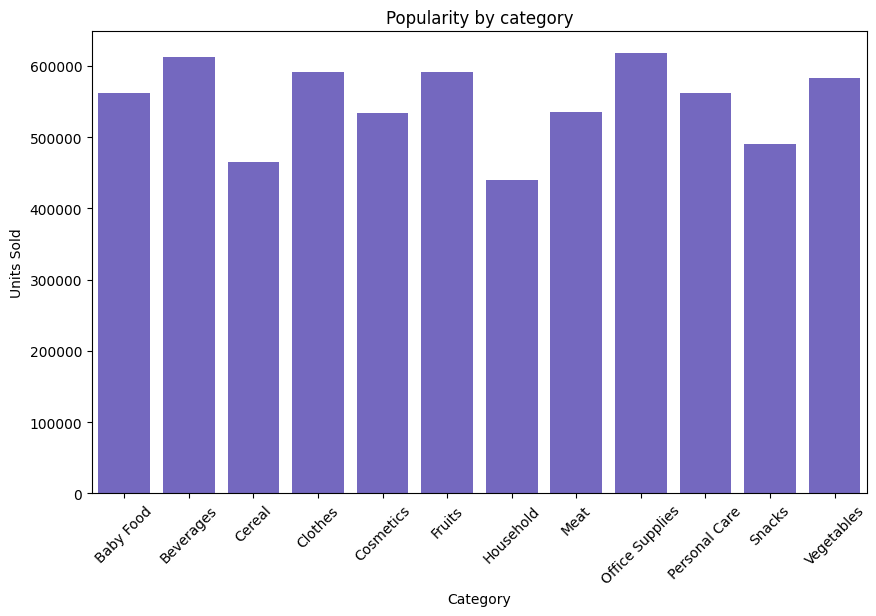

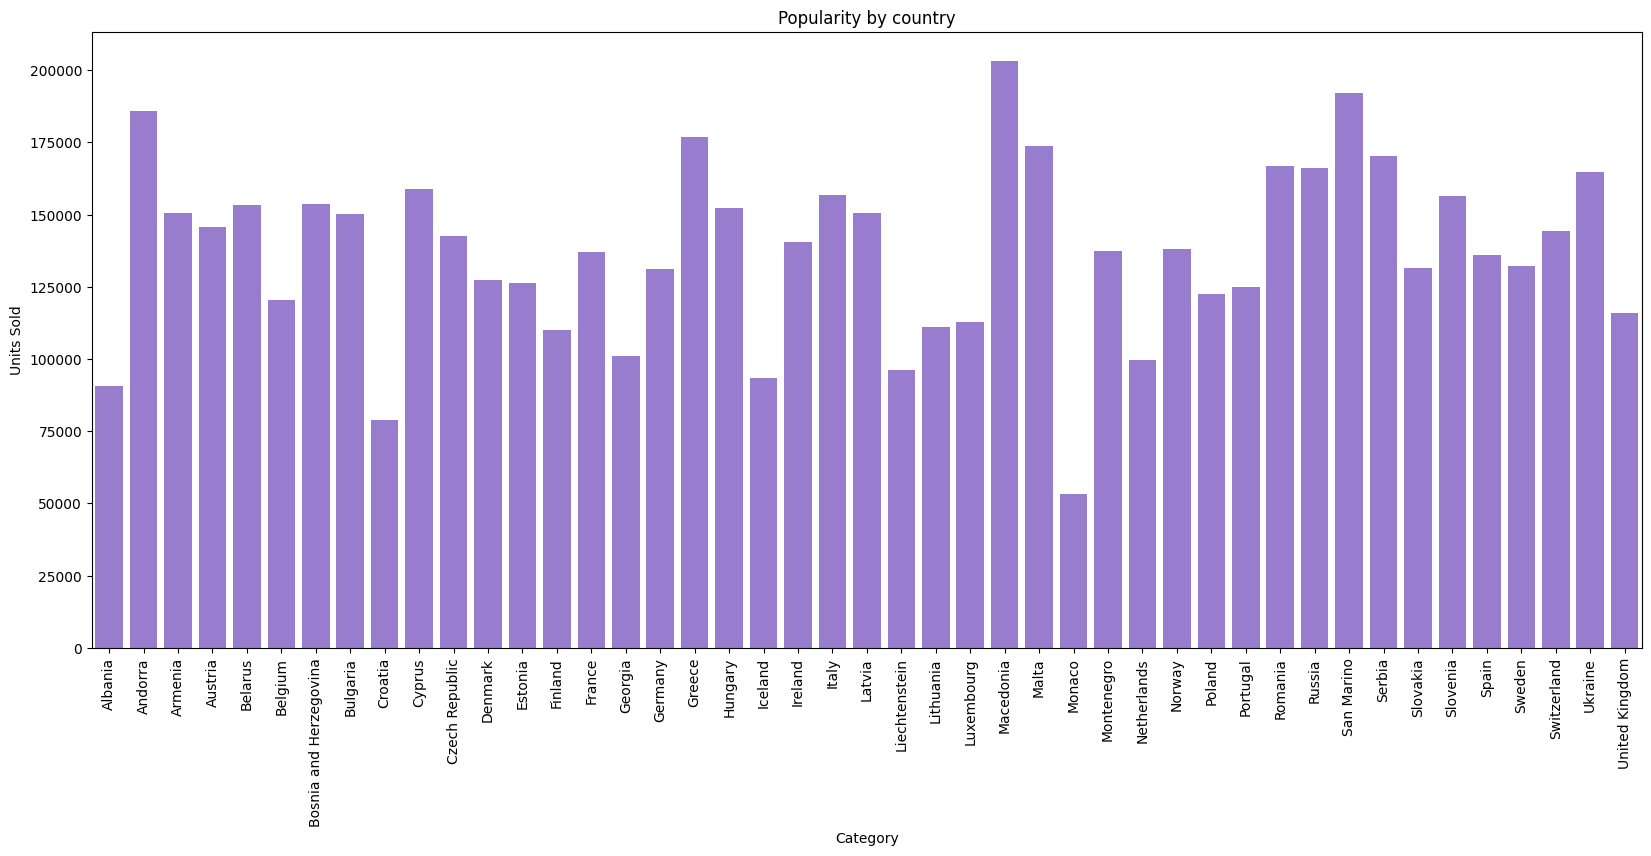

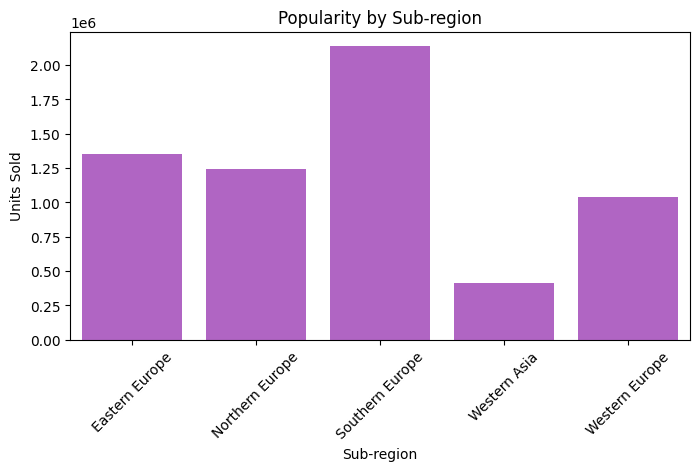

<function matplotlib.pyplot.show(close=None, block=None)>

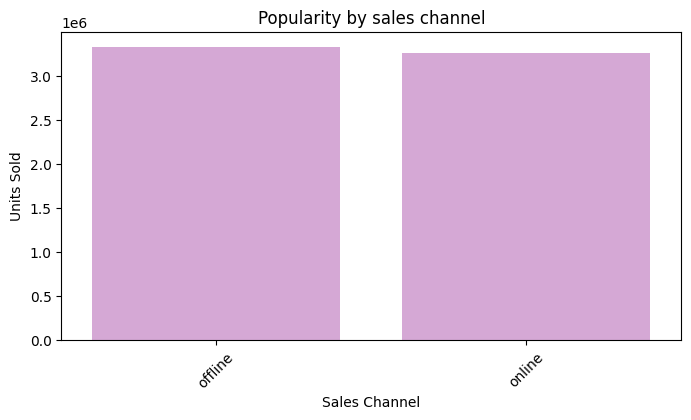

In [ ]:
# Analiza sprzedaży: popularność

# Popularność produktów według kategorii
popularity_by_category = data.groupby("Category")["Units Sold"].sum()
# Wizualizacja
plt.figure(figsize=(10, 6))
sns.barplot(x=popularity_by_category.index, y=popularity_by_category.values, color="slateblue")
plt.title("Popularity by category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.show()

# Popularność produktów według krajów
popularity_by_country = data.groupby("Country")["Units Sold"].sum()
#Wizualizacja
plt.figure(figsize=(20, 8))
sns.barplot(x=popularity_by_country.index, y=popularity_by_country.values, color="mediumpurple")
plt.title("Popularity by country")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=90)
plt.show()

# Popularność produktów według regionów
popularity_by_subregion = data.groupby("Sub-region")["Units Sold"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=popularity_by_subregion.index, y=popularity_by_subregion.values, color="mediumorchid")
plt.title("Popularity by Sub-region")
plt.xlabel("Sub-region")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.show()

# Popularność produktów według kanałów sprzedaży
popularity_by_channel = data.groupby("Sales Channel")["Units Sold"].sum()
# Wizualizacja
plt.figure(figsize=(8, 4))
sns.barplot(x=popularity_by_channel.index, y=popularity_by_channel, color="plum")
plt.title("Popularity by sales channel")
plt.xlabel("Sales Channel")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.show



Najpopularniejsze kategorie to artykuły biurowe i napoje, a najmniej popularna jest kategoria domowa. Najwięcej produktów sprzedaje się w Macedonii, San Marino i Andorze, a najmniej w Monako, Chorwacji i Albanii. Największą popularność ma region Europy Południowej, a najmniejszą region Azji Zachodniej. Sprzedaż fizyczna jest minimalnie popularniejsza od online.

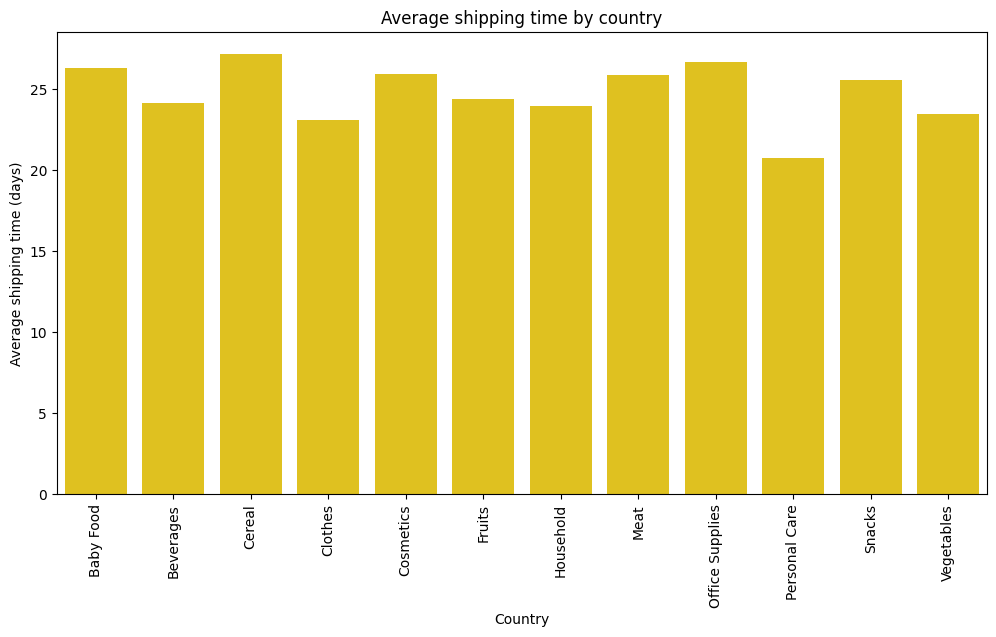

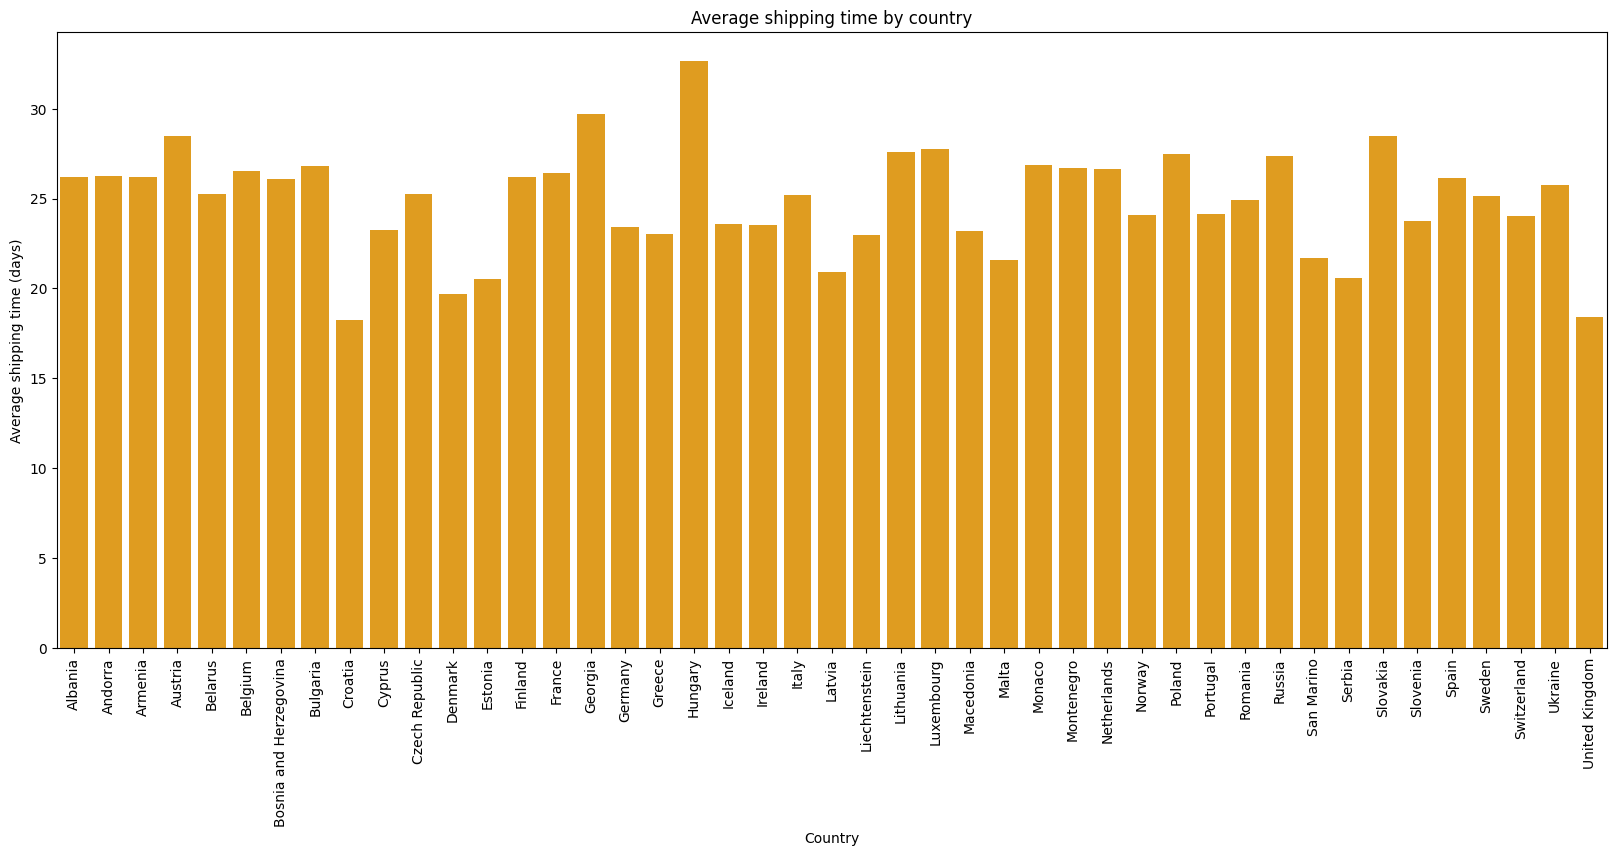

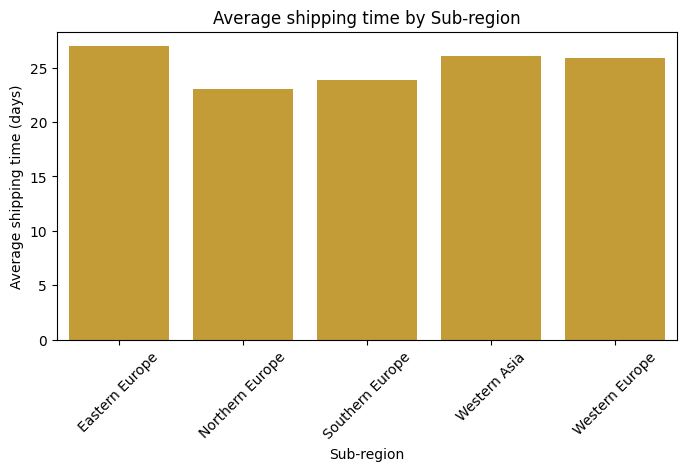

In [ ]:
# Analiza: odstęp czasu między zamówieniem a wysyłką
data[["Order Date", "Ship Date"]] = data[["Order Date", "Ship Date"]].apply(pd.to_datetime, format="%m/%d/%Y")
data["Shipping Days"] = (data["Ship Date"] - data["Order Date"]).dt.days

# Wizualizacja według kategorii produktów
shipping_by_category = (data.groupby("Category")["Shipping Days"]).mean()
plt.figure(figsize=(12, 6))
sns.barplot(x=shipping_by_category.index, y=shipping_by_category.values, color="gold")
plt.title("Average shipping time by country")
plt.xlabel("Country")
plt.ylabel("Average shipping time (days)")
plt.xticks(rotation=90)
plt.show()

# Wizualizacja według kraju
shipping_by_country = (data.groupby("Country")["Shipping Days"]).mean()
plt.figure(figsize=(20, 8))
sns.barplot(x=shipping_by_country.index, y=shipping_by_country.values, color="orange")
plt.title("Average shipping time by country")
plt.xlabel("Country")
plt.ylabel("Average shipping time (days)")
plt.xticks(rotation=90)
plt.show()

# Wizualizacja według regionu
shipping_by_subregion = (data.groupby("Sub-region")["Shipping Days"]).mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=shipping_by_subregion.index, y=shipping_by_subregion.values, color="goldenrod")
plt.title("Average shipping time by Sub-region")
plt.xlabel("Sub-region")
plt.ylabel("Average shipping time (days)")
plt.xticks(rotation=45)
plt.show()



Najdłuższy średni czas dostawy mają płatki śniadaniowe, a najkrótszy - opieka osobista. Najdłuższy średni czas dostawy jest zauważalny na Węgrzech i regionie Europy Wschodniej, a najkrótszy na Chorwacji i w Wielkiej Brytanii i w regionie Europy Północnej.

Shipping Days
0     348379.706000
1     309541.679091
2     339626.031154
3     285222.778788
4     300644.403548
5     417644.889259
6     366050.053462
7     400718.312812
8     344957.536250
9     424283.931786
10    212348.587500
11    409519.580000
12    372993.060968
13    314848.072500
14    307127.478333
15    284953.289655
16    426377.337059
17    438769.952143
18    301355.463529
19    442073.209697
20    262167.901154
21    393514.420294
22    348334.737222
23    332977.686429
24    363664.241379
25    368206.628750
26    381526.989200
27    293306.714783
28    384516.750625
29    367156.532917
30    495657.887222
31    465211.364242
32    321988.168611
33    488020.626818
34    287320.360000
35    370739.592174
36    497836.397407
37    377464.549259
38    479009.872692
39    394143.859231
40    499279.950370
41    436604.784762
42    320388.368500
43    393550.263333
44    393351.696875
45    351263.147083
46    449214.668462
47    564746.923636
48    277767.119643
49    

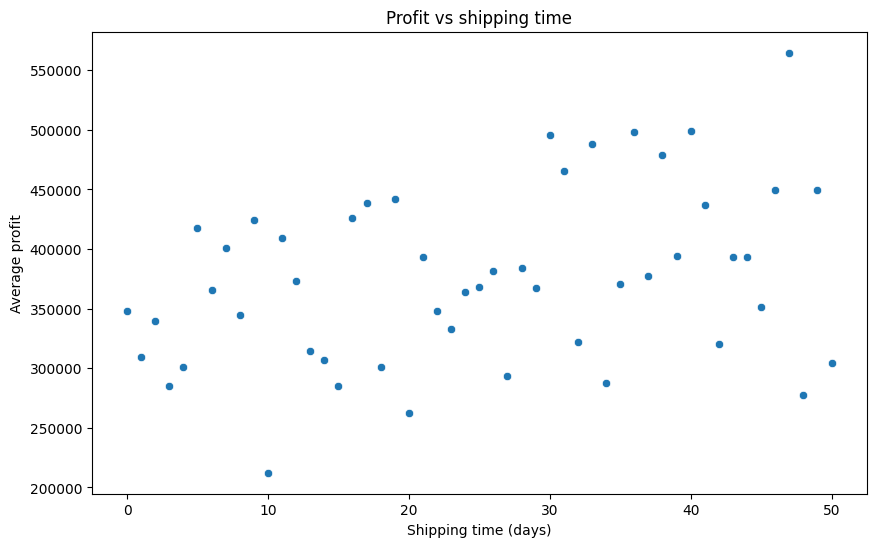

In [ ]:
# Zależność zysku od czasu potrzebnego na wysyłkę
data["Shipping Days"] = (data["Ship Date"] - data["Order Date"]).dt.days
data["Profit"] = data["Units Sold"] * (data["Unit Price"] - data["Unit Cost"])
profit_by_shipping_time = (data.groupby("Shipping Days")["Profit"].mean())
print(profit_by_shipping_time)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=profit_by_shipping_time.index,y=profit_by_shipping_time.values)
plt.title("Profit vs shipping time")
plt.xlabel("Shipping time (days)")
plt.ylabel("Average profit")
plt.show()

Punkty są mocno rozproszone na całej szerokości wykresu. Zamówienia z dłuższym czasem dostawy (30-50 dni) częściej osiągają wyższe poziomy zysku (od 450 000-550 000) niż zamówienia z krótkim czasem dostawy (0-20 dni). Najniższy zysk widoczny jest w okolicy 10 dnia dostawy - spada on do poziomu poniżej 220 000.
Najwyższy zysk jest zauważanly w okolicach 47 dnia dostawy - wynosi ponad 560 000.
Wydłużony czas dostawy nie obniża zysku


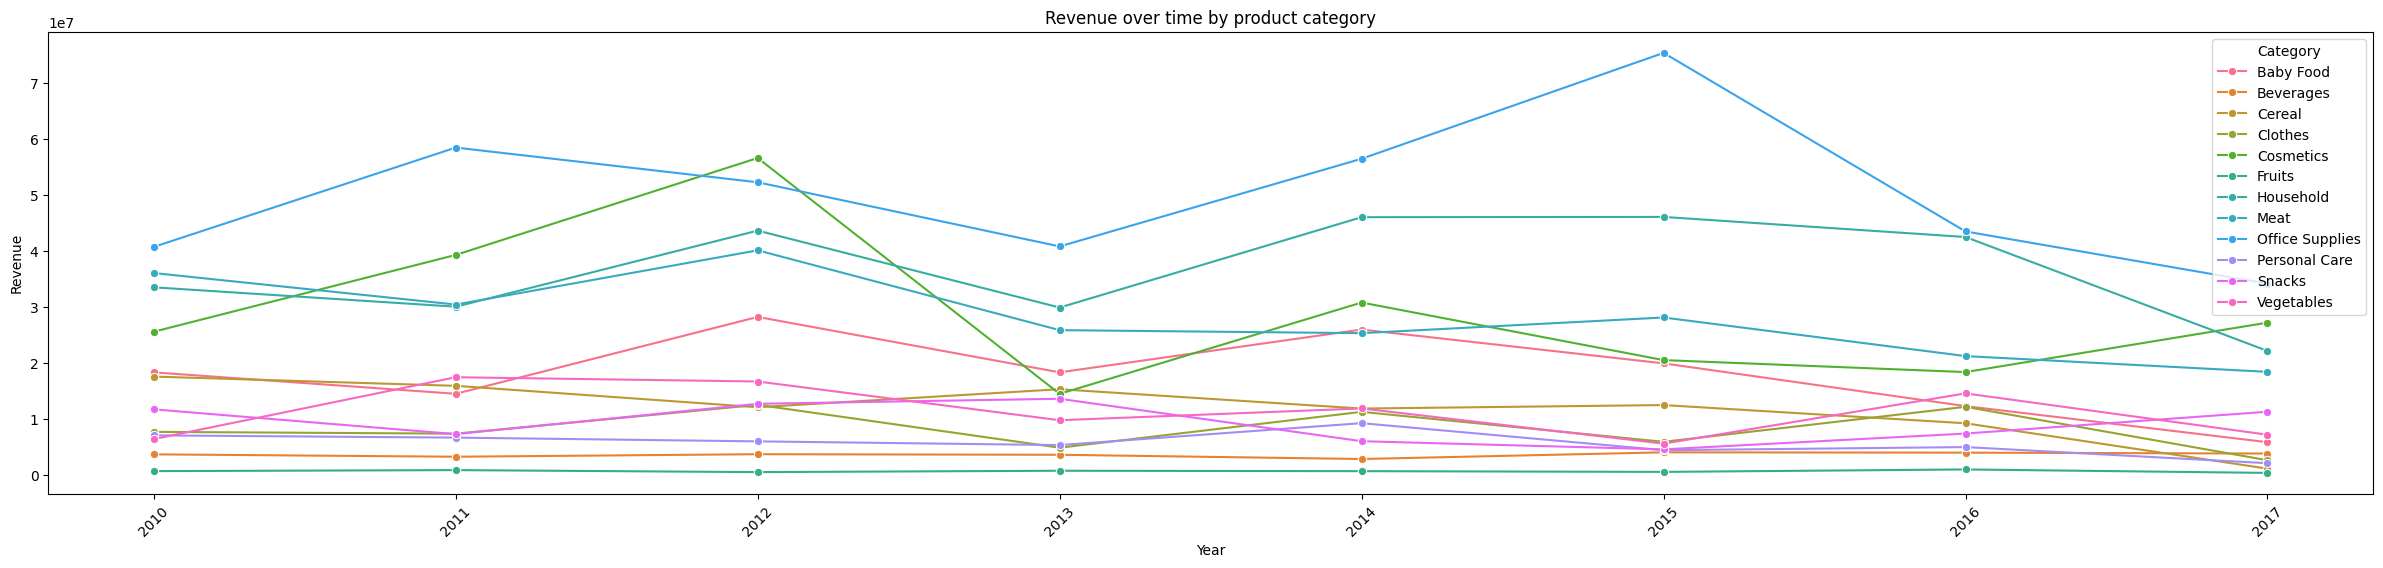

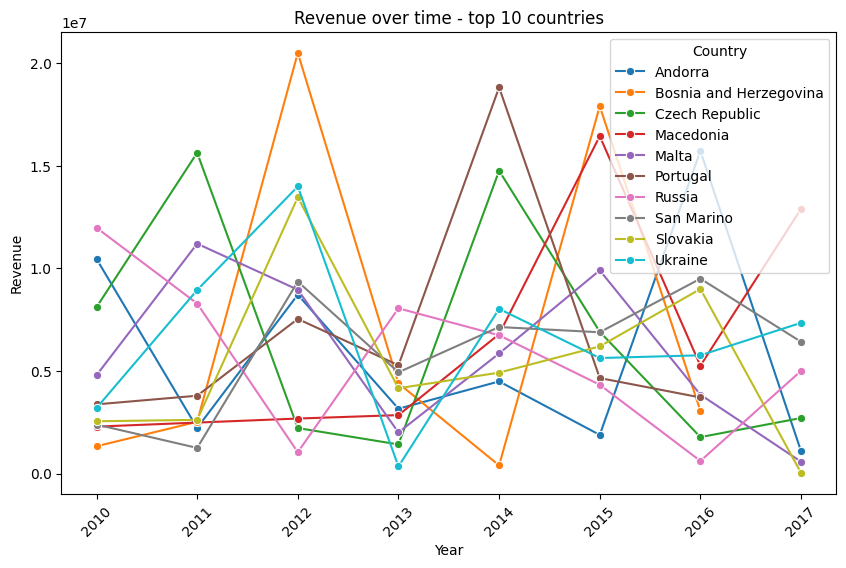

In [ ]:
# Dynamika sprzedaży

data["Revenue"] = data["Units Sold"] * data["Unit Price"]

# Wyciąganie roku z daty zamówienia
data["Year"] = data["Order Date"].dt.year

# Sprzedaż w czasie według kategorii
sales_by_category = (data.groupby(["Year", "Category"])["Revenue"].sum().reset_index())

# Wizualizacja
plt.figure(figsize=(30, 6))
sns.lineplot(data=sales_by_category, x="Year", y="Revenue", hue="Category", marker="o")
plt.title("Revenue over time by product category")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

# Sprzedaż w czasie według kraju
sales_by_country = (data.groupby(["Year", "Country"])["Revenue"].sum().reset_index())

# Krajów jest całkiem sporo, znajduję więc top 10
top_countries = (data.groupby("Country")["Revenue"].sum().nlargest(10).index)
sales_top_countries = sales_by_country[sales_by_country["Country"].isin(top_countries)]

# Wizualizacja
plt.figure(figsize=(10, 6))
sns.lineplot(data=sales_top_countries, x="Year", y="Revenue", hue="Country", marker="o")
plt.title("Revenue over time - top 10 countries")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

Na wykresie widać, że geografia sprzedaży jest niestabilna.Przychody dominują w kategoriach: Office Supplies(która osiąga szczyt w 2015 roku), Household(utrzymuje się stabilnie przez wszystkie lata)i Cosmetics(duża zmienność: wzrost w latach 2010-2012, spadek w 2013 i ponowny wzrost w 2014). Najniższe przychody generują kategorie takie jak Fruits, Beverages, Personal Care. Wśród krajów nie ma stałego lidera, w każdym kraju występują wzrosty i spadki. Bośnia i Harcegowina osiąga najwyższy przychód w 2012 roku, a później następuje gwałtowny spadek, następnej kolejny wzrost w 2015 Portugalia osiąga najwyższy wynik w 2014 roku. Większość krajów kończy rok 2017 ze znacznymi spadkami przychodów, zbliżając się do poziomu bliskiego 0. Wyjątkiem jest Macedonia, która w 2017 roku odnotowuje silny wzrost.

          Day         Category  Units Sold
0      Friday        Baby Food       79129
1      Friday        Beverages       67500
2      Friday           Cereal       62637
3      Friday          Clothes       61274
4      Friday        Cosmetics      141526
..        ...              ...         ...
79  Wednesday             Meat       89231
80  Wednesday  Office Supplies       93604
81  Wednesday    Personal Care       73676
82  Wednesday           Snacks       40413
83  Wednesday       Vegetables       95493

[84 rows x 3 columns]


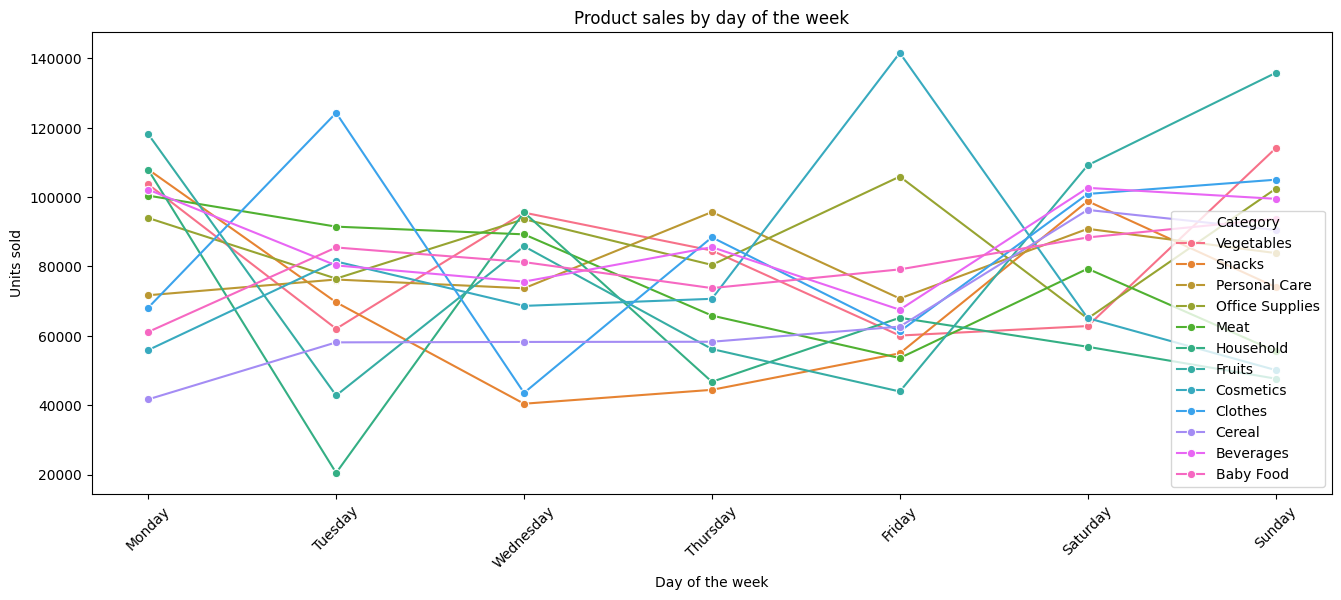

In [ ]:
# Analiza sprzedaży produktów według dni tygodnia

# wyciągam dzień tygodnia z daty zamówienia
data["Day"] = data["Order Date"].dt.day_name()

sales_by_day = (data.groupby(["Day", "Category"])["Units Sold"].sum().reset_index())
print(sales_by_day)

# porządkuję dni tygodnia
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

sales_by_day["Day"] = pd.Categorical(sales_by_day["Day"], categories=days, ordered=True)
sales_by_day = sales_by_day.sort_values("Day")

# Wizualizacja
plt.figure(figsize=(16, 6))
sns.lineplot(data=sales_by_day, x="Day", y="Units Sold", hue="Category", marker="o")

plt.title("Product sales by day of the week")
plt.xlabel("Day of the week")
plt.ylabel("Units sold")
plt.xticks(rotation=45)
plt.show()

Sprzedaż w ciągu tygodnia jest bardzo dynamiczna - określone kategorie produktów mają swoje dni szczytowe.
Cosmetics - sezonowość weekendowa (Piątek: szczyt ok. 140 000 sztuk oraz Niedziela: ok. 135 000 sztuk), podczas gdy w środę i czwartek jest o połowę niższa.
Vegetables - sezonowość niedzielna (ponad 114 000 sztuk)
Clothes - sezonowość wtorkowa:(ponad 124 000 sztuk), po czym spada w środę do ok. 43 000 sztuk.